# Generative Augmentation for 3D Alzheimer's Disease MRI Classification

## Abstract

This notebook adapts a pretrained 3D brain image generator to a new dataset and tests whether its images help a diagnosis classifier. The generator is the **MONAI Brain Latent Diffusion Model** (LDM, Pinaya et al. 2022), trained on UK Biobank. A latent diffusion model works on a compressed version of the image (the latent) produced by an autoencoder, and a UNet network learns to remove noise from the latent step by step. We fine-tune only the UNet on **OASIS-3**, a longitudinal MRI dataset on ageing and Alzheimer's disease (one MRI visit of a participant is called a session below, and a participant a subject), and give it the diagnosis of every session (the clinical scores CDR and MMSE) as an input, so that it learns how the scans of cognitively normal (CN) subjects and of subjects with Alzheimer's disease (AD) differ. Synthetic 3D T1-weighted volumes of both classes are then added to the training data of a classifier (a 3D DenseNet-121 convolutional network) that separates AD from CN sessions. We compare training on real data only with training on real plus synthetic data on a test set that shares no subjects with the training set, with three control classifiers and a bootstrap over subjects. The synthetic volumes do not raise the test AUC (area under the ROC curve): 0.828 without them and 0.804 with them, a difference inside the uncertainty of the test. The generator does carry a weak but measurable diagnosis signal: a classifier trained on synthetic volumes alone reaches 0.748 on real scans.

## Quick start on Google Colab

The full pipeline (UNet fine-tune, sampling, five classifier runs) needs OASIS-3 data and about 12 hours on one GPU. By default the notebook therefore does not train. The quick start cell below installs the packages and downloads the stored aggregate results of the experiment, and the results cell prints and plots them. Its two flags switch the training code on:

- **`LOAD_PRETRAINED_UNET`**: `True` (default) skips the UNet fine-tune (Stage 1) and the sampling (Stage 2). The cells then only define their functions. `False` runs them, which needs OASIS-3 volumes already encoded by the autoencoder (`scripts/cache_latents.py`), or a short demo when `DEMO_MODE = True`.
- **`LOAD_PRETRAINED_CLASSIFIER`**: `True` (default) skips the classifier training (Stage 3) and the paired test (Stage 4). `False` retrains the baseline and Scheme A, which needs the preprocessed OASIS-3 sessions under `/workspace/oasis3/` and a folder of synthetic volumes, or the demo data when `DEMO_MODE = True`.

> **OASIS-3 access is needed for the training paths.** OASIS-3 is distributed under a data use agreement that does not allow redistribution, so no OASIS-3 data are included here. Access can be requested at <https://www.oasis-brains.org/>. The stored results are small aggregate files in `stored_results/` of this repository, with no per-session predictions or labels. The trained weights are not distributed, because they were trained on OASIS-3 data.

> **`DEMO_MODE = True`**: if either flag is `False` and you have no OASIS-3 access, the quick start cell tries to download a demo set of 32 synthetic volumes, so that the training code can run. This demo set is not distributed either, for the same reason as the weights, so the cell prints a notice instead.

In [ ]:
LOAD_PRETRAINED_UNET       = True   # True: Stages 1 and 2 only define their code. False: run them (needs encoded OASIS-3 scans, or DEMO_MODE)
LOAD_PRETRAINED_CLASSIFIER = True   # True: Stages 3 and 4 only define their code, the results cell uses the stored results. False: retrain the baseline and Scheme A
DEMO_MODE                  = True   # If either flag is False, try to download a 32-volume synthetic demo set so the training code can run without OASIS-3 access (metrics at n=32 are not meaningful).

# Download locations. Stored results: aggregate test metrics, paired tests, ROC points and
# training histories (small JSON files in `stored_results/` of the repository).
RESULTS_URL = "https://raw.githubusercontent.com/artem-zeleniuk/mri-latent-diffusion-augmentation/main/stored_results/"
WEIGHTS_URL = "https://huggingface.co/Artem3000-dev/oasis3-aug/resolve/main/"   # demo set only, not public

# -----
# Install the Python packages the notebook needs
import subprocess, sys
def _pip(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", *pkgs])

print(">>> Installing Python dependencies (monai, nibabel, scikit-learn, scipy). "
      "Expect 3-5 minutes on a fresh Colab kernel ...", flush=True)
_pip("monai>=1.3", "nibabel", "scikit-learn", "scipy")
print(">>> dependency install complete.\n", flush=True)


from pathlib import Path
import time, urllib.error, urllib.request

WEIGHTS_DIR = Path("./weights"); WEIGHTS_DIR.mkdir(exist_ok=True)

def _fetch(name, base):
    """Download one file from `base` into WEIGHTS_DIR, unless it is already there.
    Returns the local path, or None if the file cannot be downloaded."""
    dst = WEIGHTS_DIR / name
    if dst.exists():
        print(f"  cached  : {dst}  ({dst.stat().st_size/1e3:.1f} kB)", flush=True)
        return dst
    url = base + name
    print(f"  fetching: {url}", flush=True)
    t0 = time.time()
    try:
        urllib.request.urlretrieve(url, str(dst))
    except urllib.error.URLError as e:
        if dst.exists():
            dst.unlink()
        print(f"  not available: {name} ({e}). See Data and model access in the README.\n", flush=True)
        return None
    print(f"  done    : {dst}  ({dst.stat().st_size/1e3:.1f} kB in {time.time()-t0:.0f}s)", flush=True)
    return dst

# Stored results of the five classifier runs, read by the results cell.
for _name in ("results_baseline.json", "results_A.json", "results_R.json", "results_S.json", "results_T.json", "test_extended.json", "test_roc_auc.json", "delong_results.json"):
    _fetch(_name, RESULTS_URL)
print(f"stored results in {WEIGHTS_DIR.resolve()}")

if not LOAD_PRETRAINED_UNET:
    print("LOAD_PRETRAINED_UNET=False - see Stage 1 (the fine-tune needs OASIS-3 "
          "latents encoded by the autoencoder).")
if not LOAD_PRETRAINED_CLASSIFIER:
    print("LOAD_PRETRAINED_CLASSIFIER=False - Stage 3 retrains the baseline and Scheme A "
          "(needs the preprocessed OASIS-3 sessions under /workspace/oasis3/).")

# If a flag is False and OASIS-3 is not available, fall back to a small
# synthetic demo set (32 volumes) so the training code can run.
if DEMO_MODE and (not LOAD_PRETRAINED_CLASSIFIER or not LOAD_PRETRAINED_UNET):
    import tarfile
    demo_tar = _fetch("demo_brains.tar.gz", WEIGHTS_URL)
    demo_dir = Path("./demo_brains")
    if demo_tar is None:
        print("demo dataset not available. See Data and model access in the README.")
    else:
        if not demo_dir.exists():
            print(f"  extracting demo dataset ({demo_tar.stat().st_size/1e6:.0f} MB) ...")
            with tarfile.open(demo_tar) as tf:
                tf.extractall(".")
        print(f"demo dataset ready at {demo_dir.resolve()} (32 synthetic volumes for Stages 1 to 4)")

### Stage 1: UNet fine-tune (MONAI Brain LDM on OASIS-3)

With `LOAD_PRETRAINED_UNET = True` (default) this cell defines the model code and prints a skip notice. With `LOAD_PRETRAINED_UNET = False` and `DEMO_MODE = False` the cell only prints a notice: the fine-tune needs the OASIS-3 volumes already encoded by the autoencoder, each stored with its conditioning vector (cached latents, `scripts/cache_latents.py`), and these cannot be redistributed. To run the fine-tune on your own cached latents, call `run_unet_finetune(...)` with their paths, as `scripts/run_stage.py` does. With `DEMO_MODE = True` the cell encodes the 32 demo volumes with the stock MONAI autoencoder and runs a 1-epoch fine-tune with batch size 1, only to show that the training loop runs.

In [ ]:
# Stage 1: UNet fine-tune on OASIS-3 latents.

import json, math, random, time, sys, os, types, urllib.request
from pathlib import Path
from typing import List, Union

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

from monai.networks.nets import AutoencoderKL, DiffusionModelUNet
from monai.networks.schedulers import DDIMScheduler



AUTOENCODER_KWARGS = dict(
    spatial_dims=3, in_channels=1, out_channels=1, latent_channels=3,
    channels=(64, 128, 128, 128), num_res_blocks=2,
    norm_num_groups=32, norm_eps=1e-6,
    attention_levels=(False, False, False, False),
    with_encoder_nonlocal_attn=False, with_decoder_nonlocal_attn=False,
    use_checkpoint=True,
)
DIFFUSION_KWARGS = dict(
    spatial_dims=3, in_channels=7, out_channels=3,            # 3 latent channels + 4 conditioning channels
    channels=(256, 512, 768), num_res_blocks=2,
    attention_levels=(False, True, True),
    norm_num_groups=32, norm_eps=1e-6,
    resblock_updown=True, num_head_channels=(0, 512, 768),
    with_conditioning=True, transformer_num_layers=1,
    cross_attention_dim=4, upcast_attention=True, use_flash_attention=False,
)
SCHEDULER_KWARGS = dict(
    num_train_timesteps=1000, beta_start=0.0015, beta_end=0.0205,
    schedule="scaled_linear_beta", clip_sample=False,
)
LATENT_SHAPE = (3, 20, 28, 20)
COND_DIM     = 4


class _SchedulerConfigProxy:
    """MONAI scheduler stores its config as flat attributes. This proxy forwards `.config.X`."""
    def __init__(self, scheduler):
        self._s = scheduler
    def __getattr__(self, name):
        return getattr(self._s, name)


class BrainLDMPipeline(nn.Module):
    """Frozen VAE + DiffusionUNet + DDIM scheduler, with env-var override
    for swapping the stock MONAI UNet for our fine-tuned checkpoint."""

    def __init__(self, ckpt_dir: Union[str, Path],
                 num_inference_steps: int = 50, device: str = "cuda:0"):
        super().__init__()
        ckpt_dir = Path(ckpt_dir)
        self.device = torch.device(device)
        self.autoencoder = AutoencoderKL(**AUTOENCODER_KWARGS)
        self.unet        = DiffusionModelUNet(**DIFFUSION_KWARGS)
        self.scheduler   = DDIMScheduler(**SCHEDULER_KWARGS)

        ae_path  = ckpt_dir / "models" / "autoencoder.pt"
        un_path  = ckpt_dir / "models" / "model.pt"
        ae_state = torch.load(ae_path,  map_location="cpu")
        un_state = torch.load(un_path,  map_location="cpu")
        for mod, st, lbl in [(self.autoencoder, ae_state, "autoencoder"),
                             (self.unet,        un_state, "unet")]:
            try:
                mod.load_state_dict(st)
            except RuntimeError as e:
                if hasattr(mod, "load_old_state_dict"):
                    mod.load_old_state_dict(st)
                else:
                    raise RuntimeError(f"{lbl} load failed: {e}") from e

        # Environment variables that make the pipeline load fine-tuned weights instead
        # of the stock ones (used by the live-sample demo).
        vae_override  = os.environ.get("BRAIN_LDM_VAE_OVERRIDE")
        unet_override = os.environ.get("BRAIN_LDM_UNET_OVERRIDE")
        if vae_override:
            sd = torch.load(vae_override, map_location="cpu", weights_only=False)
            sd = sd["state_dict"] if isinstance(sd, dict) and "state_dict" in sd else sd
            self.autoencoder.load_state_dict(sd)
            print(f"[BrainLDMPipeline] OVERRIDE VAE ← {vae_override}")
        if unet_override:
            sd = torch.load(unet_override, map_location="cpu", weights_only=False)
            if isinstance(sd, dict):
                sd = sd.get("ema_state_dict") or sd.get("state_dict") or sd
            self.unet.load_state_dict(sd)
            print(f"[BrainLDMPipeline] OVERRIDE UNet ← {unet_override}")

        self.autoencoder.to(self.device).eval()
        self.unet.to(self.device).eval()
        for p in self.autoencoder.parameters(): p.requires_grad_(False)
        for p in self.unet.parameters():        p.requires_grad_(False)

        self.scheduler.set_timesteps(num_inference_steps=num_inference_steps)
        self.scheduler.config = _SchedulerConfigProxy(self.scheduler)
        self.num_inference_steps = num_inference_steps

    @torch.no_grad()
    def img2latent(self, volume):
        if volume.dim() == 4: volume = volume.unsqueeze(0)
        z_mu, _ = self.autoencoder.encode(volume.to(self.device))
        return z_mu

    @torch.no_grad()
    def latent2img(self, latent):
        return self.autoencoder.decode(latent.to(self.device))

    def _build_unet_input(self, latent, cond):
        B = latent.shape[0]
        D, H, W = latent.shape[2:]
        c = cond.squeeze(1).view(B, COND_DIM, 1, 1, 1).expand(B, COND_DIM, D, H, W)
        return torch.cat([latent, c], dim=1)

    def noise_pred(self, latent, t, cond):
        if not torch.is_tensor(t):
            t = torch.tensor([t], device=self.device, dtype=torch.long)
        else:
            t = t.to(self.device).long()
        if t.dim() == 0: t = t.unsqueeze(0)
        if t.shape[0] == 1 and latent.shape[0] > 1: t = t.expand(latent.shape[0])
        x = self._build_unet_input(latent, cond)
        return self.unet(x, timesteps=t, context=cond)


def load_pipe(ckpt_dir, device="cuda:0", num_inference_steps=50):
    return BrainLDMPipeline(ckpt_dir=ckpt_dir, device=device,
                            num_inference_steps=num_inference_steps)


# Register these definitions as the module `brain_ldm`, so that
# `from brain_ldm import load_pipe` works in later cells.
_mod = types.ModuleType("brain_ldm")
for _name in ("AUTOENCODER_KWARGS", "DIFFUSION_KWARGS", "SCHEDULER_KWARGS",
              "BrainLDMPipeline", "load_pipe",
              "AutoencoderKL", "DiffusionModelUNet", "DDIMScheduler"):
    setattr(_mod, _name, globals()[_name])
sys.modules["brain_ldm"] = _mod


# Fine-tune training loop

class CachedLatentDataset(Dataset):
    """Read pre-cached .pt files holding (latent, cond) tuples."""

    def __init__(self, cache_dir: Path, session_ids: List[str],
                 cache_suffix: str = None):
        self.cache_dir = Path(cache_dir)
        if cache_suffix is None:
            for sid in session_ids:
                cands = list(self.cache_dir.glob(f"{sid}__*.pt"))
                if cands:
                    cache_suffix = cands[0].name.replace(sid, "", 1)
                    break
            if cache_suffix is None: cache_suffix = ".pt"
        self.cache_suffix = cache_suffix
        self.session_ids = [
            sid for sid in session_ids
            if (self.cache_dir / f"{sid}{cache_suffix}").is_file()
        ]

    def __len__(self):
        return len(self.session_ids)

    def __getitem__(self, idx):
        d = torch.load(self.cache_dir / f"{self.session_ids[idx]}{self.cache_suffix}",
                       map_location="cpu", weights_only=False)
        z = d["latent"].squeeze(0)              # (3, 20, 28, 20)
        c = d["cond"].squeeze(0)                # (1, 4)
        return z.float(), c.float(), d["session_id"]


class EMA:
    """Exponential moving average of model parameters."""

    def __init__(self, model: nn.Module, decay: float = 0.999):
        self.decay = decay
        self.shadow = {k: v.detach().clone() for k, v in model.state_dict().items()}

    @torch.no_grad()
    def update(self, model: nn.Module):
        for k, v in model.state_dict().items():
            if v.dtype.is_floating_point:
                self.shadow[k].mul_(self.decay).add_(v.detach(), alpha=1-self.decay)
            else:
                self.shadow[k].copy_(v.detach())

    def apply_to(self, model: nn.Module):
        model.load_state_dict(self.shadow)


def build_unet_input(latent: torch.Tensor, cond: torch.Tensor) -> torch.Tensor:
    """Latent (3-ch) + cond (4 scalars broadcast spatially) → 7-ch UNet input."""
    B, _, D, H, W = latent.shape
    if cond.dim() == 3: cond = cond.squeeze(1)
    c = cond[:, :, None, None, None].expand(B, 4, D, H, W)
    return torch.cat([latent, c], dim=1)


def diffusion_train_step(unet, scheduler, latent, cond, device):
    """DDPM noise-prediction MSE at a random timestep. fp32 MSE (bf16 would
    round the late residual to zero)."""
    B = latent.shape[0]
    t = torch.randint(0, scheduler.num_train_timesteps, (B,), device=device).long()
    noise = torch.randn_like(latent)
    noisy = scheduler.add_noise(latent, noise, t)
    x_in  = build_unet_input(noisy, cond)
    ca    = cond if cond.dim() == 3 else cond.unsqueeze(1)
    pred  = unet(x=x_in, timesteps=t, context=ca)
    return F.mse_loss(pred.float(), noise.float())


def run_unet_finetune(ckpt_dir, cache_dir, manifest_path, out_dir,
                      epochs=200, batch_size=32, lr=2.5e-5,
                      ema_decay=0.999, weight_decay=1e-2, warmup_steps=500,
                      cond_dropout=0.15, device="cuda:0", seed=42,
                      save_every=25, val_seed=1234, log_path=None):
    """Fine-tune recipe: AdamW + cosine w/linear warmup + EMA tracking. The best checkpoint
    by validation MSE of the EMA weights is kept, a full checkpoint is written every
    `save_every` epochs, and the per-epoch log goes to `log_path` (JSON) if given."""

    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    torch.cuda.manual_seed_all(seed)
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)

    print("=== loading pretrained UNet ===")
    unet = DiffusionModelUNet(**DIFFUSION_KWARGS).to(device)
    unet_path = Path(ckpt_dir) / "models" / "model.pt"
    state = torch.load(unet_path, map_location=device, weights_only=False)
    try:
        unet.load_state_dict(state, strict=True)
    except RuntimeError:
        unet.load_old_state_dict(state)
    print(f"loaded: {unet_path}")
    scheduler = DDIMScheduler(**SCHEDULER_KWARGS)

    print("=== loading cached latents ===")
    manifest = json.loads(Path(manifest_path).read_text())
    train_ds = CachedLatentDataset(cache_dir, manifest["split"]["train"])
    val_ds   = CachedLatentDataset(cache_dir, manifest["split"]["val"])
    print(f"train latents: {len(train_ds)},  val latents: {len(val_ds)}")
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False,
                              num_workers=1, pin_memory=True)

    opt = torch.optim.AdamW(unet.parameters(), lr=lr,
                            weight_decay=weight_decay, betas=(0.9, 0.999))
    total_steps = max(epochs * max(len(train_loader), 1), 1)
    warm = min(warmup_steps, max(total_steps // 4, 1))
    def lr_lambda(step):
        if step < warm:
            return float(step + 1) / float(warm)
        prog = (step - warm) / max(total_steps - warm, 1)
        return max(0.1, 0.5 * (1 + math.cos(math.pi * prog)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)

    ema = EMA(unet, decay=ema_decay)
    ema_unet = DiffusionModelUNet(**DIFFUSION_KWARGS).to(device).eval()
    for p in ema_unet.parameters(): p.requires_grad_(False)

    best_val = float("inf")
    history = []
    for epoch in range(1, epochs + 1):
        unet.train()
        t0 = time.time()
        loss_acc, n_batches = 0.0, 0
        for z, cond, _ in train_loader:
            z = z.to(device); cond = cond.to(device)
            if cond.dim() == 2: cond = cond.unsqueeze(1)
            if cond_dropout > 0:
                drop = (torch.rand(z.shape[0], device=device) < cond_dropout).view(-1, 1, 1)
                cond = torch.where(drop, torch.full_like(cond, 0.5), cond)
            opt.zero_grad()
            with torch.autocast(device_type="cuda" if device.startswith("cuda") else "cpu",
                                dtype=torch.bfloat16, enabled=device.startswith("cuda")):
                loss = diffusion_train_step(unet, scheduler, z, cond, device)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
            opt.step(); sched.step(); ema.update(unet)
            loss_acc += loss.item(); n_batches += 1
        train_loss = loss_acc / max(n_batches, 1)

        unet.eval(); ema.apply_to(ema_unet)
        val_loss = 0.0; n_val = 0
        # Same timesteps and noise at every validation pass, so the epochs are comparable.
        # The random state of the training is saved and restored around the pass.
        cpu_state = torch.random.get_rng_state()
        gpu_state = torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
        torch.manual_seed(val_seed)
        with torch.no_grad():
            for z, cond, _ in val_loader:
                z = z.to(device); cond = cond.to(device)
                if cond.dim() == 2: cond = cond.unsqueeze(1)
                val_loss += diffusion_train_step(ema_unet, scheduler, z, cond, device).item()
                n_val += 1
        torch.random.set_rng_state(cpu_state)
        if gpu_state is not None:
            torch.cuda.set_rng_state_all(gpu_state)
        val_loss = val_loss / max(n_val, 1)
        print(f"  epoch {epoch}/{epochs}  train_mse={train_loss:.5f}  val_mse_ema={val_loss:.5f}  t={time.time()-t0:.0f}s")

        if val_loss < best_val:
            best_val = val_loss
            torch.save({"epoch": epoch, "state_dict": unet.state_dict(),
                        "ema_state_dict": ema.shadow, "val_loss_ema": val_loss},
                       out_dir / "unet_oasis_finetuned_best.pt")
        if epoch % save_every == 0 or epoch == epochs:
            torch.save({"epoch": epoch, "state_dict": unet.state_dict(),
                        "ema_state_dict": ema.shadow},
                       out_dir / f"unet_epoch_{epoch}.pt")
        history.append({"epoch": epoch, "train_mse": train_loss, "val_mse_ema": val_loss,
                        "best_so_far": best_val, "time_sec": time.time() - t0})
        if log_path:
            Path(log_path).write_text(json.dumps({"epochs": history}, indent=1))




if LOAD_PRETRAINED_UNET:
    print("LOAD_PRETRAINED_UNET=True - skipping Stage 1, the fine-tuned UNet "
          "checkpoint downloaded by the quickstart is reused unchanged.")

elif not DEMO_MODE:
    print("LOAD_PRETRAINED_UNET=False and DEMO_MODE=False - this branch needs "
          "OASIS-3 latents encoded as described in the appendix (steps 0a to 0c). "
          "OASIS-3 access: https://www.oasis-brains.org. Then call "
          "run_unet_finetune(...) with the paths of the cached latents.")

else:
    # Demo run: encode the 32 demo volumes with the autoencoder, then fine-tune the UNet for 1 epoch.
    print(">>> Stage 1 DEMO retrain - encoding 32 brains through MONAI VAE, "
          "then fine-tuning UNet for 1 epoch (batch=1).", flush=True)

    import nibabel as nib

    MONAI_HF   = "https://huggingface.co/MONAI/brain_image_synthesis_latent_diffusion_model/resolve/main"
    bundle_dir = Path("./monai_bundle/brain_image_synthesis_latent_diffusion_model/models")
    bundle_dir.mkdir(parents=True, exist_ok=True)
    for fn in ("autoencoder.pt", "model.pt"):
        dst = bundle_dir / fn
        if not dst.exists():
            print(f"  fetching {fn} ...", flush=True)
            urllib.request.urlretrieve(f"{MONAI_HF}/models/{fn}", str(dst))
            print(f"    -> {dst} ({dst.stat().st_size/1e6:.1f} MB)", flush=True)

    DEV = "cuda" if torch.cuda.is_available() else "cpu"
    vae = AutoencoderKL(**AUTOENCODER_KWARGS).to(DEV).eval()
    st = torch.load(bundle_dir / "autoencoder.pt", map_location=DEV, weights_only=False)
    try:
        vae.load_state_dict(st, strict=True)
    except Exception:
        if hasattr(vae, "load_old_state_dict"):
            vae.load_old_state_dict(st)
        else: raise
    for p in vae.parameters(): p.requires_grad = False

    cache_dir = Path("./fake_cache"); cache_dir.mkdir(exist_ok=True)
    manifest = {"vae_source": "monai_bundle",
                "split": {"train": [], "val": []},
                "cached": [], "cache_suffix": "__demo.pt"}
    demo_root = Path("./demo_brains")
    items = sorted(demo_root.glob("cn/*.nii.gz")) + sorted(demo_root.glob("ad/*.nii.gz"))
    print(f"  encoding {len(items)} demo brains through VAE ...", flush=True)

    from monai.transforms import (Compose, EnsureChannelFirst, Spacing,
                                   ScaleIntensity, ResizeWithPadOrCrop)
    pre = Compose([
        EnsureChannelFirst(channel_dim="no_channel"),
        Spacing(pixdim=(1.0, 1.0, 1.0), mode="bilinear"),
        ScaleIntensity(),
        ResizeWithPadOrCrop(spatial_size=(160, 224, 160),
                            mode="constant", constant_values=0),
    ])

    def _cond_for(stem):
        return torch.tensor([[0.0, 0.7, 0.0, 0.97]] if stem.startswith("cn_")
                            else [[0.0, 0.7, 0.5, 0.5]], dtype=torch.float32)

    for idx, p in enumerate(items):
        sid = p.stem.replace(".nii", "")
        v = torch.from_numpy(nib.load(str(p)).get_fdata().astype("float32"))
        x = pre(v).unsqueeze(0).to(DEV)
        with torch.no_grad():
            z_mu, _ = vae.encode(x)
        cond = _cond_for(p.stem)
        torch.save({"session_id": sid, "latent": z_mu.cpu(),
                    "cond": cond, "metadata": {}},
                   cache_dir / f"{sid}__demo.pt")
        manifest["cached"].append(sid)
        (manifest["split"]["val"] if idx % 8 == 0
         else manifest["split"]["train"]).append(sid)
    manifest_path = cache_dir.parent / "fake_manifest.json"
    manifest_path.write_text(json.dumps(manifest, indent=2))
    print(f"  wrote {len(items)} cached latents + manifest", flush=True)
    del vae
    if DEV == "cuda": torch.cuda.empty_cache()


    run_unet_finetune(ckpt_dir=bundle_dir.parent,
                      cache_dir=cache_dir,
                      manifest_path=manifest_path,
                      out_dir="./trained_unet",
                      epochs=1, batch_size=1, device=DEV)
    print(">>> Stage 1 DEMO done, new UNet under ./trained_unet/", flush=True)


LOAD_PRETRAINED_UNET=True - skipping Stage 1, the fine-tuned UNet checkpoint downloaded by the quickstart is reused unchanged.


### Stage 2: synthetic brain generation

Sampling of synthetic volumes from the fine-tuned UNet with DDIM, a deterministic sampler that turns random noise into an image in a fixed number of denoising steps (`run_synth_generation`, 50 steps and 1000 volumes per class by default). In the experiment the function gets `cond_pool`, the conditioning vectors of the real training sessions of each class, and draws the vector of every synthetic volume from it. Without `cond_pool` the vectors come from the fixed ranges of `cond_cn` and `cond_ad`. With `LOAD_PRETRAINED_UNET = True` the cell only prints a skip notice. With `LOAD_PRETRAINED_UNET = False` and `DEMO_MODE = True` the cell samples 8 volumes per class with 10 steps from the demo UNet of Stage 1.

In [ ]:
# Stage 2: synthetic 3D brain generation with DDIM sampling.
#
# Procedure per sample:
#   1. draw the generator input c = [sex, age_norm, cdr_norm, mmse_norm] from class-specific
#      ranges. The generator reads positions 3 and 4 as ventricular volume and brain volume
#      (Section 2), so the two classes differ by these two volume inputs
#   2. draw z_T ~ N(0, I) in the (3, 20, 28, 20) VAE latent grid
#   3. run 50-step DDIM denoising with the fine-tuned UNet (an environment variable
#      makes the pipeline load the OASIS-3 fine-tuned weights instead of the stock ones)
#   4. decode the final latent via the frozen VAE
#   5. save as half-precision .pt for downstream classifier training

import os, random, time
from pathlib import Path
import torch
import numpy as np


def cond_cn(rng):
    """Cognitively-normal demographic prior: CDR=0, normal MMSE."""
    g = rng.choice([0.0, 1.0])
    a = rng.uniform(0.5, 0.95)
    mmse = rng.uniform(27, 30) / 30.0
    return [g, a, 0.0, mmse]


def cond_ad(rng):
    """Alzheimer's-disease demographic prior: CDR 0.5 to 2.0, impaired MMSE."""
    g = rng.choice([0.0, 1.0])
    a = rng.uniform(0.6, 0.95)
    cdr  = rng.uniform(0.5, 2.0) / 3.0
    mmse = rng.uniform(10, 24) / 30.0
    return [g, a, cdr, mmse]


def ddim_sample(pipe, z_T, cond, steps, device):
    """Plain DDIM (η = 0) sampling: clean latent → decoded volume."""
    pipe.scheduler.set_timesteps(num_inference_steps=steps)
    z = z_T.clone()
    with torch.no_grad():
        for t in pipe.scheduler.timesteps.to(device):
            tb = torch.tensor([t.item()] * z.shape[0], device=device)
            eps = pipe.noise_pred(z, tb, cond)
            z, _ = pipe.scheduler.step(eps, t, z, eta=0.0)
        return pipe.latent2img(z)


def run_synth_generation(ckpt_base, unet_finetuned, out_dir,
                         n_per_class=1000, steps=50, device="cuda:0", seed=42, cond_pool=None):
    """Sample CN/AD synthetic volumes via DDIM and save as half-precision .pt.

    cond_pool: optional {"cn": [...], "ad": [...]} with the conditioning vectors of the real
    training sessions of each class. Each synthetic volume then takes the vector of a randomly
    drawn session of its class. Without it the vectors come from cond_cn and cond_ad.
    Every volume has its own random generator and existing files are skipped, so an
    interrupted run can be continued."""

    out = Path(out_dir)
    (out / "cn").mkdir(parents=True, exist_ok=True)
    (out / "ad").mkdir(parents=True, exist_ok=True)
    torch.manual_seed(seed); np.random.seed(seed)

    # Set the environment variable before building the pipeline, so it loads the fine-tuned UNet.
    os.environ["BRAIN_LDM_UNET_OVERRIDE"] = str(unet_finetuned)
    print("loading fine-tuned pipe ...")
    pipe = load_pipe(str(ckpt_base), device=device, num_inference_steps=steps)
    print("ready")

    rng = random.Random(seed)
    for ci, (cls, cond_fn) in enumerate([("cn", cond_cn), ("ad", cond_ad)]):
        print(f"\n=== {cls} ({n_per_class} samples) ===")
        t0 = time.time()
        for i in range(n_per_class):
            # drawn for every index, so the sequence does not depend on restarts
            c = list(rng.choice(cond_pool[cls])) if cond_pool else cond_fn(rng)
            dst = out / cls / f"{cls}_{i:04d}.pt"
            if dst.exists():
                continue
            gen  = torch.Generator(device=device).manual_seed(seed * 1000003 + ci * 100003 + i)
            z_T  = torch.randn(1, 3, 20, 28, 20, device=device, generator=gen)
            cond = torch.tensor([[c]], device=device, dtype=torch.float32)
            img  = ddim_sample(pipe, z_T, cond, steps, device)
            tmp  = out / cls / f"{cls}_{i:04d}.tmp.pt"
            torch.save(img.half().cpu(), tmp)
            tmp.rename(dst)
            if (i + 1) % 50 == 0:
                el = time.time() - t0
                eta = (n_per_class - i - 1) * el / (i + 1)
                print(f"  [{i+1}/{n_per_class}] elapsed={el:.0f}s ETA={eta:.0f}s")
    print("\nDONE")




if LOAD_PRETRAINED_UNET:
    print("LOAD_PRETRAINED_UNET=True - skipping Stage 2. The synthetic volumes "
          "of the reported classifiers are not downloaded by the quickstart.")

elif not DEMO_MODE:
    print("LOAD_PRETRAINED_UNET=False and DEMO_MODE=False - Stage 2 needs an "
          "OASIS-3-fine-tuned UNet. Run Stage 1 on OASIS-3 latents first, or "
          "set DEMO_MODE = True to sample from the demo-retrained UNet.")

else:
    # Pick the latest demo checkpoint produced by Stage 1.
    ckpts = sorted(Path("./trained_unet").glob("unet_epoch_*.pt"))
    if ckpts:
        unet_finetuned = ckpts[-1]
    else:
        unet_finetuned = Path("./trained_unet/unet_oasis_finetuned_best.pt")
    bundle = Path("./monai_bundle/brain_image_synthesis_latent_diffusion_model")
    if not unet_finetuned.exists() or not (bundle / "models" / "model.pt").exists():
        print(">>> Stage 2 SKIPPED: missing fine-tuned UNet or stock bundle. "
              "Run Stage 1 first.")
    else:
        DEV = "cuda:0" if torch.cuda.is_available() else "cpu"
        run_synth_generation(ckpt_base=bundle, unet_finetuned=unet_finetuned,
                             out_dir="./synth", n_per_class=8, steps=10,
                             device=DEV, seed=42)


LOAD_PRETRAINED_UNET=True - skipping Stage 2. The synthetic volumes of the reported classifiers are not downloaded by the quickstart.


### Stage 3: AD classifier (baseline, Scheme A and the controls)

Training of the 3D DenseNet-121 classifier with `run_scheme`. The baseline is trained on real OASIS-3 sessions only, and Scheme A on real and synthetic volumes mixed in the same batches. The function also holds the three controls of the experiment: R (real sessions only, with the number of optimiser steps of Scheme A), S (as Scheme A, with the labels of the synthetic volumes permuted) and T (synthetic volumes only). With `LOAD_PRETRAINED_CLASSIFIER = True` the cell only defines the training code, and the results cell below uses the stored results. With `False`, it trains the baseline and then Scheme A. On OASIS-3 this reads `/workspace/oasis3/labels.json` and the synthetic volumes in `/workspace/synth`, with 20 epochs and batch size 4. The experiment itself ran all five schemes for 50 epochs through `scripts/run_stage.py`. In demo mode the cell reads the labels of the 32 demo volumes and the Stage 2 demo samples (2 epochs, batch size 1). The weights and the test metrics (`results_*.json`) are written to `./trained/`.

In [ ]:
# Stage 3: downstream 3D AD classifier (DenseNet-121).
#

import json, random, time
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
import torch.nn as nn
import nibabel as nib
from torch.utils.data import Dataset, DataLoader

from monai.networks.nets import DenseNet121
from monai.transforms import (Compose, ScaleIntensity, ResizeWithPadOrCrop,
                              RandFlip, RandGaussianNoise, RandRotate)
from sklearn.metrics import roc_auc_score, balanced_accuracy_score


def load_split(labels_path, seed=42):
    """Subject-disjoint 70/15/15 split stratified by majority label per subject."""
    data = json.load(open(labels_path))
    by_subj = defaultdict(list)
    for sid, info in data.items():
        by_subj[info["subject"]].append(info)

    subj_majority = {s: int(np.round(np.mean([x["y"] for x in v])))
                     for s, v in by_subj.items()}
    cn_subs = [s for s, l in subj_majority.items() if l == 0]
    ad_subs = [s for s, l in subj_majority.items() if l == 1]
    rng = random.Random(seed)
    rng.shuffle(cn_subs); rng.shuffle(ad_subs)

    def split(subs):
        n = len(subs); n_tr = int(.7*n); n_va = int(.15*n)
        return subs[:n_tr], subs[n_tr:n_tr+n_va], subs[n_tr+n_va:]

    cn_tr, cn_va, cn_te = split(cn_subs)
    ad_tr, ad_va, ad_te = split(ad_subs)

    splits = {}
    for name, subj_list in [("train", cn_tr+ad_tr), ("val", cn_va+ad_va), ("test", cn_te+ad_te)]:
        sessions = []
        for s in subj_list:
            sessions.extend(by_subj[s])
        rng.shuffle(sessions)
        splits[name] = sessions
        n_ad = sum(x["y"] for x in sessions)
        print(f"{name:5s}: {len(sessions)} sessions / {len(subj_list)} subjects  (AD={n_ad}, CN={len(sessions)-n_ad})")
    return splits


def load_volume(path):
    """Load .nii.gz -> (1, D, H, W) float32 tensor."""
    v = nib.load(path).get_fdata().astype(np.float32)
    return torch.from_numpy(v).unsqueeze(0)


def load_synth(pt_path):
    """Load synth .pt -> (1, D, H, W) float32 tensor, limited to [0, 1].

    The autoencoder was trained on volumes scaled to [0, 1]. Its decoder undershoots in a few
    voxels (minimum near -0.15), and without the limit the min-max scaling of the classifier
    input lifts the whole background of a synthetic volume to about 0.13 (real volumes: 0.005)."""
    img = torch.load(pt_path, map_location="cpu", weights_only=False)
    return img[0].float().clamp(0.0, 1.0)


class BrainDataset(Dataset):
    """Preloaded into RAM. Preprocessing runs at init, augmentation in __getitem__."""

    def __init__(self, items, target_size, augment=False):
        self.items = items
        pre = Compose([ScaleIntensity(),
                       ResizeWithPadOrCrop(spatial_size=tuple(target_size))])
        self.aug = Compose([
            RandFlip(prob=0.5, spatial_axis=0),
            RandGaussianNoise(prob=0.3, mean=0, std=0.025),
            RandRotate(range_x=0.087, range_y=0.087, range_z=0.087,
                       prob=0.3, padding_mode="zeros"),
        ]) if augment else None

        print(f"  preloading {len(items)} volumes to RAM (target {tuple(target_size)})...")
        t0 = time.time()
        self.cache = []
        kept = []
        n_skip = 0
        for i, item in enumerate(items):
            v = load_synth(item["synth_path"]) if "synth_path" in item else load_volume(item["path"])
            v = pre(v).contiguous()
            if torch.isnan(v).any() or v.std() < 1e-6:
                n_skip += 1
                continue
            self.cache.append(v.half())
            kept.append(item)
            if (i+1) % 200 == 0:
                ram = sum(c.numel()*2 for c in self.cache) / 1024**3
                print(f"    {i+1}/{len(items)}  elapsed {time.time()-t0:.0f}s  RAM={ram:.1f}GB")
        self.items = kept
        ram = sum(c.numel()*2 for c in self.cache) / 1024**3
        print(f"  preload done in {time.time()-t0:.0f}s, RAM {ram:.2f}GB, skipped {n_skip}")

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        v = self.cache[i].float()
        if self.aug:
            v = self.aug(v)
        return v, torch.tensor(self.items[i]["y"], dtype=torch.long)


def collate_stack(items):
    vols = torch.stack([x[0] for x in items])
    ys   = torch.stack([x[1] for x in items])
    return vols, ys


def make_loader(items, batch, shuffle, target_size, augment=False, num_workers=2, epoch_items=None):
    """epoch_items: number of items drawn per epoch, as whole random permutations of the set one
    after another (default: every item once)."""
    ds = BrainDataset(items, target_size=target_size, augment=augment)
    sampler = (torch.utils.data.RandomSampler(ds, replacement=False, num_samples=epoch_items)
               if epoch_items else None)
    return DataLoader(ds, batch_size=batch, shuffle=shuffle and sampler is None, sampler=sampler,
                      num_workers=num_workers, collate_fn=collate_stack, pin_memory=True,
                      persistent_workers=num_workers > 0)


def get_synth_items(synth_dir):
    cn = [{"synth_path": str(p), "y": 0} for p in sorted(Path(synth_dir).glob("cn/*.pt")) if ".tmp" not in p.name]
    ad = [{"synth_path": str(p), "y": 1} for p in sorted(Path(synth_dir).glob("ad/*.pt")) if ".tmp" not in p.name]
    print(f"synth: CN={len(cn)} AD={len(ad)}")
    return cn + ad


def evaluate(model, loader, device):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            p = torch.softmax(model(x), dim=1)[:, 1]
            probs.append(p.cpu()); ys.append(y.cpu())
    probs = torch.cat(probs).numpy()
    ys    = torch.cat(ys).numpy()
    auc  = roc_auc_score(ys, probs) if len(set(ys)) > 1 else float("nan")
    bacc = balanced_accuracy_score(ys, (probs > 0.5).astype(int))
    return auc, bacc, probs, ys


def bootstrap_ci(metric_fn, ys, probs, n=1000, seed=42):
    rng = np.random.RandomState(seed)
    vals, skipped = [], 0
    for _ in range(n):
        idx = rng.randint(0, len(ys), len(ys))
        try:
            vals.append(metric_fn(ys[idx], probs[idx]))
        except ValueError:
            skipped += 1
    if skipped:
        print(f"  [bootstrap] skipped {skipped}/{n} (single-class resample)")
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


def class_weights_from(items, use_weights=True):
    """Weights = N/(2·n_class) over the items given. run_scheme passes the list the classifier
    trains on, so the two classes carry the same total loss weight with and without synthetic
    volumes. (Weights of the real sessions alone, applied to a pool with 1000 + 1000 synthetic
    volumes, would put about half of the loss weight on the synthetic AD class.)"""
    ys = [x["y"] for x in items]
    n_cn = sum(1 for y in ys if y == 0)
    n_ad = sum(1 for y in ys if y == 1)
    if n_cn == 0 or n_ad == 0:
        return None
    if not use_weights:
        return None
    w_cn = (n_cn + n_ad) / (2 * n_cn)
    w_ad = (n_cn + n_ad) / (2 * n_ad)
    return torch.tensor([w_cn, w_ad], dtype=torch.float32)


def train_one(model, train_loader, val_loader, epochs, lr, device, tag,
              out_dir, ckpt_name, class_weights=None, lr_schedule="cosine"):
    trainable = [p for p in model.parameters() if p.requires_grad]
    print(f"  trainable params: {sum(p.numel() for p in trainable)/1e6:.2f}M")
    optim = torch.optim.Adam(trainable, lr=lr)
    sched = (torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=epochs, eta_min=lr*0.1)
             if lr_schedule == "cosine" else None)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device)) if class_weights is not None \
              else nn.CrossEntropyLoss()
    if class_weights is not None:
        print(f"  class weights: {class_weights.tolist()}")
    best_auc = 0.0
    history = []
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        losses = []
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            optim.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(trainable, max_norm=1.0)
            optim.step()
            losses.append(loss.item())
        if sched:
            sched.step()
        val_auc, val_bacc, _, _ = evaluate(model, val_loader, device)
        avg_loss = float(np.mean(losses))
        history.append({"ep": ep+1, "loss": avg_loss, "val_auc": val_auc,
                        "val_bacc": val_bacc, "lr": optim.param_groups[0]["lr"]})
        print(f"  [{tag} ep{ep+1}/{epochs}] loss={avg_loss:.4f} val_auc={val_auc:.4f} "
              f"val_bacc={val_bacc:.4f}  t={time.time()-t0:.0f}s")
        if val_auc > best_auc or not (Path(out_dir) / ckpt_name).exists():
            best_auc = val_auc if val_auc == val_auc else best_auc   # keep the previous best value if val_auc is NaN
            torch.save(model.state_dict(), Path(out_dir) / ckpt_name)
    return history


def run_scheme(scheme, labels_path, synth_dir, out_dir, epochs, batch, lr,
               device, target_size, lr_schedule="cosine", seed=42, num_workers=2):
    """Train + test one scheme end-to-end.

    baseline  real training sessions
    A         real sessions + synthetic volumes
    R         control: real sessions only, as many items per epoch as Scheme A (same number of
              optimiser steps as A)
    S         control: as A, with the labels of the synthetic volumes permuted
    T         control: synthetic volumes only (validation and test on real sessions as always)"""
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    print(f"\n=== scheme: {scheme} ===")

    splits = load_split(labels_path, seed=seed)
    assert scheme in ("baseline", "A", "R", "S", "T"), scheme
    synth_items = get_synth_items(synth_dir) if scheme != "baseline" else []
    if scheme == "S":
        ys = [x["y"] for x in synth_items]
        random.Random(seed).shuffle(ys)
        synth_items = [dict(x, y=y) for x, y in zip(synth_items, ys)]

    val_loader  = make_loader(splits["val"],  batch, False, target_size, num_workers=num_workers)
    test_loader = make_loader(splits["test"], batch, False, target_size, num_workers=num_workers)

    # Instance normalisation, because a batch of 4 is too small for stable batch-normalisation statistics.
    model = DenseNet121(spatial_dims=3, in_channels=1, out_channels=2,
                        norm="instance").to(device)

    real = splits["train"]
    train_items = {"baseline": real, "R": real, "A": real + synth_items,
                   "S": real + synth_items, "T": synth_items}[scheme]
    epoch_items = len(real) + len(synth_items) if scheme == "R" else None
    n_synth = len(synth_items) if scheme in ("A", "S", "T") else 0

    class_w = class_weights_from(train_items)
    if class_w is not None:
        print(f"\nclass weights: CN={class_w[0]:.3f} AD={class_w[1]:.3f}")

    print(f"\n--- train on {len(train_items)} items (real={len(train_items) - n_synth}, synth={n_synth}), "
          f"{epoch_items or len(train_items)} items per epoch ---")
    train_loader = make_loader(train_items, batch, True, target_size, augment=True,
                               num_workers=num_workers, epoch_items=epoch_items)

    ckpt_name = f"best_{scheme}.pt" if scheme != "baseline" else "best_baseline.pt"
    history = train_one(model, train_loader, val_loader, epochs, lr, device,
                        scheme, out_dir, ckpt_name, class_weights=class_w,
                        lr_schedule=lr_schedule)

    # Test on best checkpoint.
    test_ckpt = out / ckpt_name
    print(f"\nloading test checkpoint: {test_ckpt}")
    model.load_state_dict(torch.load(test_ckpt, map_location=device, weights_only=True))
    test_auc, test_bacc, probs, ys = evaluate(model, test_loader, device)
    auc_lo, auc_hi = bootstrap_ci(lambda y, p: roc_auc_score(y, p), ys, probs)
    bacc_lo, bacc_hi = bootstrap_ci(
        lambda y, p: balanced_accuracy_score(y, (p > 0.5).astype(int)), ys, probs)

    print(f"\n=== TEST RESULTS [{scheme}] ===")
    print(f"  AUC:  {test_auc:.4f}  [95% CI {auc_lo:.4f}, {auc_hi:.4f}]")
    print(f"  bACC: {test_bacc:.4f} [95% CI {bacc_lo:.4f}, {bacc_hi:.4f}]")

    json.dump({"scheme": scheme, "test_auc": float(test_auc),
               "test_bacc": float(test_bacc),
               "auc_ci": [auc_lo, auc_hi], "bacc_ci": [bacc_lo, bacc_hi],
               "history": history, "n_train_real": len(train_items) - n_synth,
               "n_synth": n_synth, "items_per_epoch": epoch_items or len(train_items),
               "class_weights": None if class_w is None else [float(w) for w in class_w],
               "n_val": len(splits["val"]), "n_test": len(splits["test"])},
              open(out / f"results_{scheme}.json", "w"), indent=2, default=float)


if LOAD_PRETRAINED_CLASSIFIER:
    print("LOAD_PRETRAINED_CLASSIFIER=True - skipping Stage 3, "
          "the summary cells below use the stored results in ./weights/.")
else:
    if DEMO_MODE:
        labels   = "./demo_brains/labels.json"
        synth    = "./synth"                # Stage 2 demo output (cn/, ad/)
        epochs, batch = 2, 1
    else:
        labels   = "/workspace/oasis3/labels.json"
        synth    = "/workspace/synth"
        epochs, batch = 20, 4

    if not Path(labels).exists():
        print(f">>> Stage 3 SKIPPED: labels file not found at {labels}.")
        print(">>> Mount OASIS-3 first, set DEMO_MODE = True, or keep "
              "LOAD_PRETRAINED_CLASSIFIER = True.")
    else:
        DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
        for scheme in ("baseline", "A"):
            run_scheme(scheme, labels_path=labels, synth_dir=synth,
                       out_dir="./trained", epochs=epochs, batch=batch,
                       lr=1e-5, device=DEVICE,
                       target_size=[160, 220, 160], lr_schedule="cosine")
        print(">>> Stage 3 done, checkpoints under ./trained/")


LOAD_PRETRAINED_CLASSIFIER=True - skipping Stage 3, the summary cells below use the stored results in ./weights/.


### Stage 4: DeLong paired AUC test

Final test-set evaluation. The DeLong test checks whether two AUCs measured on the same test sessions differ by more than chance, taking into account that both classifiers see the same cases. With `LOAD_PRETRAINED_CLASSIFIER = True` the cell is skipped, and the results cell below uses the stored `delong_results.json` and `test_roc_auc.json`. With `False`, it evaluates the Stage 3 weights on the test split with `run_delong_eval` and writes `delong_results.json` and `test_roc_auc.json` (ROC points, no per-session values) to `./weights/`. The DeLong test treats the sessions as independent. The evaluation of the experiment (`scripts/run_stage.py`) therefore adds a bootstrap over subjects, which the results below use as the main statistic.

In [ ]:
# Stage 4: DeLong paired AUC test on the same test set.
#
# Loads both checkpoints from Stage 3, evaluates each on the held-out test
# set, caches per-session probabilities, then runs DeLong's paired test for the
# difference AUC_A - AUC_baseline, which accounts for both classifiers being
# scored on the same test sessions.

import json
from pathlib import Path
import numpy as np
import torch
import scipy.stats as ss
from sklearn.metrics import roc_auc_score, roc_curve


def delong_paired(y, p1, p2):
    """DeLong (1988) paired two-AUC test. Cov(AUC_1, AUC_2) in closed form via the
    V10/V01 structural components, which accounts for the shared test set."""

    def midrank(x):
        """Mid-ranks: tied values share the average of their tied positions."""
        order = np.argsort(x)
        ranks = np.empty_like(order, dtype=float)
        i = 0
        while i < len(x):
            j = i
            while j + 1 < len(x) and x[order[j+1]] == x[order[i]]:
                j += 1
            avg = 0.5 * (i + j) + 1
            for k in range(i, j + 1):
                ranks[order[k]] = avg
            i = j + 1
        return ranks

    def auc_components(p_pos, p_neg):
        m, n = len(p_pos), len(p_neg)
        all_p = np.concatenate([p_pos, p_neg])
        T  = midrank(all_p)
        TP = midrank(p_pos); TN = midrank(p_neg)
        Tpos = T[:m]; Tneg = T[m:]
        V10 = (Tpos - TP) / n
        V01 = 1 - (Tneg - TN) / m
        return V10, V01, V10.sum() / m

    auc1 = roc_auc_score(y, p1)
    auc2 = roc_auc_score(y, p2)
    pos = y == 1; neg = y == 0
    m, n = pos.sum(), neg.sum()
    V10_1, V01_1, a1 = auc_components(p1[pos], p1[neg])
    V10_2, V01_2, a2 = auc_components(p2[pos], p2[neg])

    S10 = np.cov(np.stack([V10_1, V10_2]))
    S01 = np.cov(np.stack([V01_1, V01_2]))
    cov = S10 / m + S01 / n
    var_delta = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    if var_delta <= 0:
        z, p = 0.0, 1.0
    else:
        z = (a2 - a1) / np.sqrt(var_delta)
        p = 2 * (1 - ss.norm.cdf(abs(z)))
    return auc1, auc2, auc2 - auc1, var_delta, z, p


def run_delong_eval(labels_path, ckpts, names, out_dir, device,
                    batch=1, target_size=(160, 220, 160)):
    """Evaluate each ckpt on the same test split, save probs, then DeLong-test."""
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    splits = load_split(labels_path)
    test_loader = make_loader(splits["test"], batch, False, list(target_size))

    probs_all, ys_ref = {}, None
    for name, ckpt in zip(names, ckpts):
        print(f"\n=== eval {name}  ({ckpt}) ===")
        model = DenseNet121(spatial_dims=3, in_channels=1,
                            out_channels=2, norm="instance").to(device)
        model.load_state_dict(torch.load(ckpt, map_location=device,
                                         weights_only=True))
        auc, bacc, probs, ys = evaluate(model, test_loader, device)
        print(f"  AUC={auc:.4f}  bACC={bacc:.4f}  N={len(ys)}")
        probs_all[name] = probs
        if ys_ref is None:
            ys_ref = ys
        else:
            assert np.array_equal(ys, ys_ref), f"{name} got different y from baseline"
        np.save(out / f"probs_{name}.npy", probs)
        del model
        torch.cuda.empty_cache()
    np.save(out / "y_test.npy", ys_ref)

    # Aggregate ROC points (no per-session values), read by the summary cells.
    roc = {"n_test": int(len(ys_ref)), "n_ad": int((ys_ref == 1).sum()),
           "n_cn": int((ys_ref == 0).sum()), "schemes": {}}
    for name in names:
        fpr, tpr, _ = roc_curve(ys_ref, probs_all[name])
        roc["schemes"][name] = {"auc": float(roc_auc_score(ys_ref, probs_all[name])),
                                "fpr": fpr.tolist(), "tpr": tpr.tolist()}
    json.dump(roc, open(out / "test_roc_auc.json", "w"), indent=1)

    print("\n\nDELONG PAIRED TESTS")
    results = {}
    for name in names[1:]:
        auc_b, auc_t, delta, var_d, z, p_val = delong_paired(
            ys_ref, probs_all["baseline"], probs_all[name])
        print(f"\n{name} vs baseline:")
        print(f"  AUC baseline: {auc_b:.4f}")
        print(f"  AUC {name}: {auc_t:.4f}")
        print(f"  Δ:    {delta:+.4f}")
        print(f"  SE:   {np.sqrt(var_d):.4f}   z: {z:.3f}")
        print(f"  p (two-sided): {p_val:.4f}   significant @ 0.05: {p_val < 0.05}")
        results[f"{name}_vs_baseline"] = {
            "auc_baseline": float(auc_b), "auc_compare": float(auc_t),
            "delta": float(delta), "var_delta": float(var_d),
            "se_delta": float(np.sqrt(var_d)), "z": float(z),
            "p_value": float(p_val), "significant_05": bool(p_val < 0.05),
        }
    json.dump(results, open(out / "delong_results.json", "w"), indent=2)
    print(f"\nSaved: {out}/delong_results.json")



if LOAD_PRETRAINED_CLASSIFIER:
    print("LOAD_PRETRAINED_CLASSIFIER=True - skipping Stage 4, the stored "
          "DeLong results in ./weights/ feed the summary cells below.")
else:
    labels_path = "./demo_brains/labels.json" if DEMO_MODE else "/workspace/oasis3/labels.json"
    ckpt_b = Path("./trained/best_baseline.pt")
    ckpt_a = Path("./trained/best_A.pt")
    if not Path(labels_path).exists():
        print(f">>> Stage 4 SKIPPED: labels file not found at {labels_path}.")
    elif not (ckpt_b.exists() and ckpt_a.exists()):
        print(">>> Stage 4 SKIPPED: missing ./trained/best_baseline.pt or "
              "./trained/best_A.pt. Either rerun Stage 3, or keep "
              "LOAD_PRETRAINED_CLASSIFIER = True to use the stored results.")
    else:
        DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
        run_delong_eval(labels_path=labels_path,
                        ckpts=[str(ckpt_b), str(ckpt_a)],
                        names=["baseline", "A"],
                        out_dir="./weights",
                        device=DEVICE, batch=1)
        print(">>> Stage 4 done, updated ROC and DeLong files in ./weights/")


LOAD_PRETRAINED_CLASSIFIER=True - skipping Stage 4, the stored DeLong results in ./weights/ feed the summary cells below.


## 1. Motivation and background

Alzheimer's disease classification from structural MRI is limited by the size of labelled datasets. Generative augmentation, that is, adding images from a generative model to the training data, is one way to get more training examples:

- **Pinaya et al. (2022)** released a brain LDM trained on T1-weighted MRI of 31,740 UK Biobank participants (healthy adults aged 44 to 82).
- **Dhinagar et al. (2024)** pretrained a 3D DenseNet-121 on synthetic scans from an LDM trained on ADNI, then fine-tuned it on real scans. The test AUC of AD classification rose from 0.866 to 0.887 (2.1 percentage points).
- **BrLP (Puglisi et al. 2024)** trains its own LDM, with the architecture of Pinaya et al. (2022), on 11,730 T1-weighted scans from ADNI, OASIS-3 and AIBL. **LDAE (Lozupone et al. 2026)** starts its autoencoder from the UK Biobank weights of Pinaya et al. (2022) and trains a new latent diffusion model on about 10,000 ADNI scans.

The task here is different: the pretrained UK Biobank model is adapted to OASIS-3 by fine-tuning only its UNet, with a small compute budget and fewer scans than these works used.

**Why could synthetic volumes help at all?** The generator and the classifier learn from the same training sessions, so the synthetic volumes hold no information about the disease that these sessions do not hold. The idea of this kind of augmentation is different. The generator was pretrained on 31,740 UK Biobank participants and knows far more brain anatomy than the 1674 OASIS-3 training sessions show. If it combines this knowledge with what it learns about AD from OASIS-3, it can draw new, plausible AD and CN brains, and it can fill up the smaller class (337 AD against 1337 CN training sessions). The experiment tests whether this happens.

## 2. Method

### 2.1 Pipeline

```
OASIS-3 raw T1w MRI
  ↓ rigid registration (rotation and translation only) to the MNI152 template with ANTs
  ↓ encode with the frozen Pinaya autoencoder → latents of shape (3, 20, 28, 20)
  ↓ fine-tune the Pinaya UNet on the latents of the training sessions, with sex, age, CDR and MMSE of each session as inputs
  ↓ 50-step DDIM sampling with the inputs of a real training session of the wanted class, decode with the autoencoder, limit to [0, 1] → synthetic 3D brain volumes
  ↓ 3D DenseNet-121 classifier, trained on real data only (baseline) or on real plus synthetic data (Scheme A), and three controls
```

MNI152 is a standard brain template (an average of 152 brains), and ANTs is image registration software. Rigid registration only rotates and shifts each head into the standard position, without changing its size or shape. It matches the UniRes preprocessing of the pretrained model, which registers each head rigidly to MNI space at 1 mm (Pinaya et al. 2022).

### 2.2 How the generator learns the two classes

The pretrained generator has four inputs between 0 and 1: sex, age, ventricular volume and brain volume (MONAI bundle, `configs/inference.json`). In the fine-tune the four inputs hold `[sex, age, CDR/3, MMSE/30]` of each session. The Clinical Dementia Rating (CDR) and the Mini-Mental State Examination score (MMSE) are those of the clinical visit nearest to the scan (`scripts/build_labels.py`, `scripts/cache_latents.py`). The two inputs that meant volumes in the pretrained model now hold the diagnosis, in the same direction: a higher CDR where a larger ventricular volume was, a lower MMSE where a smaller brain volume was. In the 1674 training sessions the conditioning has 1337 sessions with CDR 0, 247 with CDR 0.5, 82 with CDR 1 and 8 with CDR 2, and 932 sessions of women and 742 of men (`conditioning_stats.json`).

The fine-tune uses only the 1674 training sessions of the classifier split and chooses its checkpoint on the 397 validation sessions, so no subject of the test split reaches the generator.

### 2.3 Stage 1: UNet fine-tune

| Hyperparameter | Value |
|---|---|
| Optimizer | AdamW, learning rate 2.5e-5, weight decay 1e-2 |
| Learning-rate schedule | linear increase over the first 500 steps, then cosine decay to 10% of the peak |
| EMA | exponential moving average of the weights with decay 0.999, a smoothed copy of the weights used for validation and sampling |
| Mixed precision | network in bf16 (16-bit floating point), loss in fp32 (32-bit) |
| Batch | 32 |
| Epochs | 100 (code default 200). The checkpoint with the lowest validation MSE of the EMA weights is kept: epoch 46, validation MSE 0.1235 (after the first epoch 0.1513, after the last 0.1329, `unet_fine_tune_log.json`) |
| Validation | after every epoch the model predicts the noise added to the latents of the validation sessions, with the same timesteps and noise at every epoch, so the epochs are comparable |
| Conditioning dropout | 15%: the conditioning vector is replaced by a neutral value (0.5), so the model also learns to denoise without it. This is the recipe of classifier-free guidance (Ho and Salimans 2022), which allows the conditioning to be strengthened at sampling time. The sampling here does not use this option |

The validation MSE is the mean squared error of the predicted noise on the validation latents. The autoencoder is frozen.

### 2.4 Stage 2: synthetic generation

With the kept UNet checkpoint, 1000 volumes are sampled for each of the two classes (CN and AD) with 50-step DDIM. Each volume gets the conditioning vector of a randomly drawn real training session of its class, so the synthetic CN and AD volumes follow the real mix of sex, age, CDR and MMSE.

**Limit to [0, 1].** The decoder of the autoencoder undershoots in a few voxels, with a minimum near -0.15. The classifier scales every volume by its minimum and maximum, so without a limit the whole background of a synthetic volume would be lifted to 0.131, against 0.006 for real volumes, and the median tissue intensity would drop to 0.164 against 0.271 (60 volumes each, `generator_checks.json`). The decoder output is therefore limited to [0, 1] before the classifier scales it. The synthetic background is then 0.005 and the median tissue intensity 0.275.

### 2.5 Stage 3: 3D AD classifier

| Hyperparameter | Value | Source |
|---|---|---|
| Architecture | MONAI DenseNet121 (3D) with instance normalisation | 3D DenseNet-121 as in Dhinagar et al. 2024 and Termine et al. 2022. Instance normalisation (our choice) normalises each volume on its own, because batch normalisation needs batches larger than 4 |
| Optimizer | Adam, learning rate 1e-5 | as in Termine et al. 2022 (MONAI 3D DenseNet-121). Wen et al. 2020 used Adam with learning rate 1e-4 for AD versus CN |
| Learning-rate schedule | cosine decay to 10% of the start value (CosineAnnealingLR) | our choice |
| Batch | 4 | small enough for GPU memory with 3D volumes |
| Epochs | 50. The epoch with the best validation AUC is kept | at the maximum of 50 of Wen et al. 2020 |
| Loss | cross-entropy weighted by the inverse class frequency of the items the classifier trains on | standard |
| Input | 3D volume of 160×220×160 voxels, padded or cropped to this size without resampling | our choice |
| Augmentation | random left-right flip, Gaussian noise (σ = 0.025), random rotation up to ±5° per axis | our choice |
| Gradient clipping | gradient norm limited to 1.0 | precaution |

### 2.6 Schemes

The effect of the synthetic volumes is tested with five ways of training the classifier, each of which answers its own question:

| Scheme | Training items | Items per epoch | Question |
|---|---|---|---|
| Baseline | 1674 real | 1674 | reference without synthetic data |
| A | 1674 real and 2000 synthetic | 3674 | do the synthetic volumes help |
| R (control) | 1674 real | 3674, drawn as whole random permutations of the real set | is a difference of A explained by its larger number of optimiser steps (45950 against 20950) |
| S (control) | as A, with the labels of the synthetic volumes permuted | 3674 | do the labels of the synthetic volumes matter |
| T (control) | 2000 synthetic | 2000 | does a classifier that never saw a real scan recognise real AD |

For each classifier the epoch with the best validation AUC on the real validation sessions is kept and tested once on the 382 test sessions (74 AD, 308 CN, 161 subjects). In Scheme A the class weights are CN 0.786 and AD 1.374.

## 3. Dataset

**OASIS-3** (LaMontagne et al. 2019) is a longitudinal dataset on ageing and Alzheimer's disease. Its current release has 1378 participants and 2842 MR sessions, which include T1-weighted (T1w) and other sequences (OASIS-3 web page). Many subjects have several sessions.

Sessions leave the pipeline at two steps. Preprocessing keeps sessions with a T1w volume registered to MNI152. Label extraction (`scripts/build_labels.py`) keeps sessions of subjects with at least one CDR score in the clinical table of the Knight Alzheimer Disease Research Center (ADRC) that comes with OASIS-3, and gives each session the CDR of the nearest clinical visit. The split (`load_split` in Stage 3) then assigns every labelled session to train, validation or test, 70/15/15 by subject.

| | Sessions | Subjects | AD sessions | CN sessions |
|---|---|---|---|---|
| OASIS-3 release, all MR sessions | 2842 | 1378 | not labelled at this step | not labelled at this step |
| Labelled sessions used here | 2453 | 1068 | 480 | 1973 |
| Training | 1674 | 747 | 337 | 1337 |
| Validation | 397 | 160 | 69 | 328 |
| Test | 382 | 161 | 74 | 308 |

**Split by subject.** No subject appears in more than one of the train, validation and test splits, so scans of the same person cannot leak from training into testing. The generator is fine-tuned on the training sessions and validated on the validation sessions of this same split.

Labels come from the CDR (0 = no dementia, 0.5 = very mild, 1 = mild, 2 = moderate, 3 = severe): CDR = 0 is CN (`y = 0`) and CDR ≥ 0.5 is AD (`y = 1`). The MMSE is not used for the labels. The classes are imbalanced, and the weighted cross-entropy loss compensates for this during training.

## 4. Results

The experiment was run in November 2026 on one GPU with the code of Stages 1 to 4 of this notebook and the scripts in `scripts/`, with one seed (42). The cell below prints the stored results and draws the test AUC with its interval, the ROC curves and the validation AUC per epoch and per optimiser step. Several sessions of one subject are not independent, so the intervals and p-values in the first columns come from a bootstrap over subjects (2000 resamples, every subject drawn with all of its test sessions). The DeLong test, which treats the sessions as independent, is printed next to it.

test split: 382 sessions (74 AD, 308 CN) of 161 subjects
scheme                                   test AUC  95 % interval (subjects)    bACC  kept epoch  val AUC
Baseline (real)                            0.8284        0.760 to 0.888        0.724          24    0.828
Scheme A (real + synthetic)                0.8044        0.725 to 0.870        0.650          20    0.821
Control R (real, steps of A)               0.8403        0.771 to 0.899        0.718          14    0.826
Control S (synthetic labels permuted)      0.7840        0.707 to 0.857        0.704          27    0.810
Control T (synthetic only)                 0.7480        0.668 to 0.825        0.708          14    0.788

difference             delta AUC  95 % interval (subjects)  p (subjects)  p (DeLong, sessions)
A minus baseline         -0.0240       -0.072 to +0.018             0.260                0.2024
R minus baseline         +0.0118       -0.016 to +0.041             0.426                0.2872
S minus baseline    

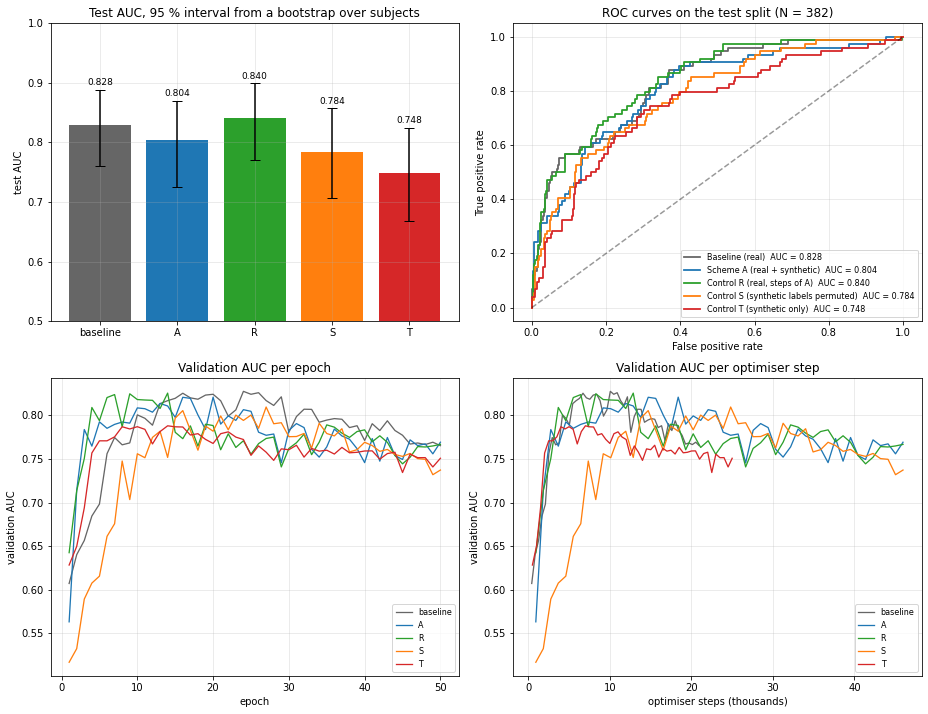

In [ ]:
# Stored results of the five classifier runs (baseline, Scheme A, controls R, S and T).
# Needs the quick start cell, which puts the stored result files into ./weights/.
import json
from pathlib import Path
from sklearn.metrics import auc
import matplotlib.pyplot as plt

W = Path("./weights")
SCHEMES = ["baseline", "A", "R", "S", "T"]
NAMES = {"baseline": "Baseline (real)", "A": "Scheme A (real + synthetic)", "R": "Control R (real, steps of A)",
         "S": "Control S (synthetic labels permuted)", "T": "Control T (synthetic only)"}
COLORS = {"baseline": "#666666", "A": "#1f77b4", "R": "#2ca02c", "S": "#ff7f0e", "T": "#d62728"}

res = {s: json.load(open(W / f"results_{s}.json")) for s in SCHEMES}
ext = json.load(open(W / "test_extended.json"))["all"]
roc = json.load(open(W / "test_roc_auc.json"))
delong = json.load(open(W / "delong_results.json"))
val = {s: [r["val_auc"] for r in res[s]["history"]] for s in SCHEMES}
steps = {s: -(-res[s].get("items_per_epoch", res[s]["n_train_real"]) // 4) for s in SCHEMES}   # optimiser steps per epoch, batch 4

print(f"test split: {ext['n_sessions']} sessions ({ext['n_ad']} AD, {ext['n_cn']} CN) of {ext['n_subjects']} subjects")
print(f"{'scheme':40s} {'test AUC':>8s}  {'95 % interval (subjects)':>24s}  {'bACC':>6s}  {'kept epoch':>10s}  {'val AUC':>7s}")
for s in SCHEMES:
    best = max(res[s]["history"], key=lambda r: r["val_auc"])
    lo, hi = ext["auc"][s]["ci95"]
    print(f"{NAMES[s]:40s} {ext['auc'][s]['auc']:8.4f}  {lo:11.3f} to {hi:.3f}{'':5s}  {res[s]['test_bacc']:6.3f}  {best['ep']:10d}  {best['val_auc']:7.3f}")
print()
print(f"{'difference':22s} {'delta AUC':>9s}  {'95 % interval (subjects)':>24s}  {'p (subjects)':>12s}  {'p (DeLong, sessions)':>20s}")
for k, v in ext["difference"].items():
    a, b = k.split("_minus_")
    p_dl = f"{delong[a + '_vs_baseline']['p_value']:.4f}" if b == "baseline" else "not computed"
    print(f"{a + ' minus ' + b:22s} {v['delta']:+9.4f}  {v['ci95'][0]:+11.3f} to {v['ci95'][1]:+.3f}{'':4s}  {v['p_two_sided']:12.3f}  {p_dl:>20s}")
print()
print("validation AUC early in training (mean over the epochs)")
print(f"{'scheme':40s} {'steps per epoch':>15s}  {'epochs 1 to 5':>13s}  {'epochs 1 to 10':>14s}")
for s in SCHEMES:
    print(f"{NAMES[s]:40s} {steps[s]:15d}  {sum(val[s][:5]) / 5:13.3f}  {sum(val[s][:10]) / 10:14.3f}")
base_ep = [max(1, min(50, round(e * steps["A"] / steps["baseline"]))) for e in range(1, 6)]
print(f"baseline at the optimiser steps of epochs 1 to 5 of Scheme A (its epochs {base_ep}): "
      f"{sum(val['baseline'][e - 1] for e in base_ep) / 5:.3f}")

fig, ax = plt.subplots(2, 2, figsize=(13, 10))
ax = ax.ravel()
for i, s in enumerate(SCHEMES):
    lo, hi = ext["auc"][s]["ci95"]
    v = ext["auc"][s]["auc"]
    ax[0].bar(i, v, color=COLORS[s], yerr=[[v - lo], [hi - v]], capsize=5)
    ax[0].text(i, hi + 0.008, f"{v:.3f}", ha="center", fontsize=9)
    fpr, tpr = roc["schemes"][s]["fpr"], roc["schemes"][s]["tpr"]
    ax[1].plot(fpr, tpr, color=COLORS[s], lw=1.8, label=f"{NAMES[s]}  AUC = {auc(fpr, tpr):.3f}")
    ax[2].plot(range(1, len(val[s]) + 1), val[s], color=COLORS[s], lw=1.3, label=s)
    ax[3].plot([e * steps[s] / 1000 for e in range(1, len(val[s]) + 1)], val[s], color=COLORS[s], lw=1.3, label=s)
ax[0].set_xticks(range(len(SCHEMES)))
ax[0].set_xticklabels(SCHEMES)
ax[0].set_ylim(0.5, 1.0)
ax[0].set_ylabel("test AUC")
ax[0].set_title("Test AUC, 95 % interval from a bootstrap over subjects")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[1].set_xlabel("False positive rate")
ax[1].set_ylabel("True positive rate")
ax[1].set_title(f"ROC curves on the test split (N = {roc['n_test']})")
ax[1].legend(loc="lower right", fontsize=8)
ax[2].set_xlabel("epoch")
ax[2].set_title("Validation AUC per epoch")
ax[3].set_xlabel("optimiser steps (thousands)")
ax[3].set_title("Validation AUC per optimiser step")
for a_ in (ax[2], ax[3]):
    a_.set_ylabel("validation AUC")
    a_.legend(loc="lower right", fontsize=8)
for a_ in ax:
    a_.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### 4.1 Test-set performance

| Scheme | Test AUC | 95 % interval (bootstrap over subjects) | Difference to the baseline | 95 % interval of the difference | p |
|---|---|---|---|---|---|
| Baseline, real only | 0.8284 | 0.760 to 0.888 | 0 (reference) | not applicable (reference) | not applicable (reference) |
| A, real and synthetic | 0.8044 | 0.725 to 0.870 | -0.0240 | -0.072 to +0.018 | 0.26 |
| R, real only, steps of A | 0.8403 | 0.771 to 0.899 | +0.0118 | -0.016 to +0.041 | 0.43 |
| S, as A with permuted synthetic labels | 0.7840 | 0.707 to 0.857 | -0.0444 | -0.102 to +0.011 | 0.12 |
| T, synthetic only | 0.7480 | 0.668 to 0.825 | -0.0804 | -0.142 to -0.019 | 0.006 |

The AUCs are those of the evaluation stage. Sources: `test_extended.json`, `results_*.json`, `delong_results.json`.

**How to read the intervals and p-values.** The 95 % interval of a difference is the range that holds the difference in 95 % of the resampled test sets. If the interval includes zero, the data are compatible with no difference at all. The p-value says how often a difference of this size would appear by chance if the two schemes were in truth equal, and by convention a difference counts as shown only when p is below 0.05.

- **No gain from the synthetic volumes.** Scheme A is below the baseline by 0.0240 AUC, and the interval of the difference includes zero. Against control R, which has the same number of optimiser steps, the difference is -0.0358 (-0.084 to +0.007, p = 0.11).
- **More steps alone do not hurt.** Control R is 0.0118 above the baseline. This difference too cannot be told from zero (interval -0.016 to +0.041, p = 0.43).
- **No evidence that the labels of the synthetic volumes matter at the end of training.** Scheme A minus control S is +0.0204 (-0.063 to +0.101, p = 0.62).
- **Synthetic volumes alone carry a signal that transfers to real scans.** Control T, trained on no real scan, reaches 0.7480 on the real test sessions. This is not all diagnosis: the conditioning vectors are those of real sessions, and the AD sessions are older (76.6 against 68.3 years in a sample of 80 and 80 training sessions, `real_proxies_reference.json`), so part of what T learned is age.
- **Subgroups.** Inside the larger of the two storage grids (182 × 218 × 182 voxels, 308 test sessions, 68 AD) the baseline has 0.815, Scheme A 0.812 and control R 0.836. For CN against CDR 1 or higher (21 AD sessions) the baseline has 0.872 and Scheme A 0.865. All subgroups are in `test_extended.json`.

### 4.2 Early in training

**A weak classifier gains from more steps, not from the synthetic volumes.** Early in training the classifier with synthetic volumes looks better than the baseline: over the first 5 epochs the mean validation AUC is 0.724 for Scheme A and 0.657 for the baseline (first 10 epochs: 0.759 and 0.715). But an epoch of Scheme A has 2.2 times more optimiser steps (919 against 419). Control R, which has the same number of steps as Scheme A and no synthetic volumes, is at 0.742 over the first 5 epochs (0.778 over the first 10). At equal numbers of optimiser steps the three are level: over the first 4595 steps the baseline is at 0.733 (its epochs 2, 4, 7, 9 and 11), Scheme A at 0.724 and control R at 0.742. A comparison after a fixed, small number of epochs would therefore show a gain for the synthetic volumes that comes from the longer training alone. The labels of the synthetic volumes do matter in this phase: with permuted labels (control S) the mean over the first 5 epochs is 0.572. These are validation values of single runs.

### 4.3 Do the synthetic volumes differ by the requested diagnosis

Four checks, all in `stored_results/` (`generator_checks.json`, `synthetic_class_check.json`).

1. **Noise-prediction error with true and altered conditioning** (397 validation sessions, the same noise for every variant). Permuting sex and age between sessions raises the error of the fine-tuned UNet by 0.260 %, permuting CDR and MMSE by 0.010 %. Replacing the diagnosis values by those of the other class raises the error for 80 % of the AD sessions but only for 16 % of the CN sessions (mean change over all sessions -0.022 %). For the stock UNet, which reads these two inputs as volumes, the same replacement changes the error by -0.292 %. The fine-tune lowered the error itself by 15 to 43 %, depending on the timestep. So the fine-tuned UNet uses sex and age clearly and the diagnosis weakly, and for CN sessions the CN code (CDR 0) is still slightly worse than the code of very mild dementia, a rest of the old meaning of this input (ventricular volume).
2. **Pairs from the same noise** (24 pairs, sex and age of a real training session, only CDR and MMSE changed). The share of dark voxels in a central box, where the lateral ventricles are, is 0.085 for the CN vector and rises by 0.023 for CDR 0.5 and by 0.037 for CDR 1. The stock UNet starts at 0.011 and rises by 0.048 and 0.114. On real training sessions AD is higher than CN by 0.049, not matched for age. The baseline classifier, which never saw a synthetic volume, gives the CN vector a mean p(AD) of 0.029 and a higher value for CDR 0.5 in 23 of 24 pairs (mean difference +0.033) and for CDR 1 in 24 of 24 pairs (mean difference +0.086). For the stock UNet the two mean differences are -0.001 and 0.000. Changing only MMSE changes nothing (mean difference 0.000).
3. **The baseline classifier on the 2000 synthetic volumes.** It separates synthetic AD from synthetic CN with an AUC of 0.732 (on the real validation sessions 0.828, on their autoencoder reconstructions 0.832). But the synthetic AD class is mild: mean p(AD) is 0.139 for synthetic AD and 0.045 for synthetic CN, against 0.554 and 0.133 for real AD and CN, and the classifier calls 10.5 % of the synthetic AD volumes AD, against 61 % of the real ones. Mean p(AD) rises with the CDR of the conditioning vector: 0.118 for CDR 0.5 (760 volumes), 0.199 for CDR 1 (219) and 0.286 for CDR 2 (21). Over all synthetic volumes p(AD) correlates more with the age input (Spearman 0.56) than with the CDR input (0.41).
4. **No copies of training sessions.** In the latent space of the autoencoder the nearest training latent of a synthetic volume is at a median distance of 155 (CN) and 156 (AD), against 164 for real validation sessions of other subjects and 109 between two sessions of one subject. None of 500 synthetic volumes is closer than 125, and the closest validation session is at 124. The spread of the synthetic volumes is narrower than that of real ones: the standard deviation of the central dark-voxel share is 0.035 over 24 synthetic CN volumes and 0.148 over 80 real CN sessions.

## 5. Discussion

### What the experiment shows

The generator does produce different scans for the two requested diagnoses, and a classifier trained on real scans recognises the difference. The difference is weak, as expected for an AD class that is mostly very mild dementia (73 % of its training sessions have CDR 0.5), and nine synthetic AD volumes out of ten look like CN volumes to the classifier. Such volumes add little to the 1674 real training sessions, since the generator was fine-tuned on these same sessions: its samples can restate what the sessions say about the disease but cannot add to it. A generator trained on more scans than the classifier sees could add information. The gain reported by Dhinagar et al. (2024) is 0.021 AUC, below what this test split can resolve, so a gain of that size is neither confirmed nor excluded here.

### Earlier version of the pipeline

An earlier version of this pipeline did not pass the diagnosis to the fine-tune of the generator (as far as its code and the clinical table show, its data loader matched no row of the table, so every session got default inputs) and requested the two classes only at sampling time, through the two volume inputs of the pretrained model. Its synthetic volumes also entered the classifier without the limit to [0, 1], with the shifted background described in the method (measured on stored volumes of that version). In that version a short classifier run showed a gain from the synthetic volumes and a longer run did not. Because of these two defects those runs are not reported here. The comparison of the first epochs in the results shows how such a gain can arise from the larger number of training steps alone.

### Limitations and confounds

1. **One seed and one split.** The standard error of the difference between Scheme A and the baseline is 0.022 (bootstrap over subjects), so a true difference below about 0.04 in either direction cannot be told from zero. The spread between training runs was not measured. The augmentation of the classifier is not fixed by the seed, so a rerun gives slightly different numbers.
2. **The split was used before.** The earlier version of the pipeline was evaluated on the same split. The settings of this experiment, including the class weights, the limit to [0, 1] and the controls, were fixed before any of its test results existed.
3. **Sessions of one subject are correlated.** The DeLong test treats them as independent, so the bootstrap over subjects is the main result and the DeLong p-values are shown only next to it.
4. **Labels.** Each session gets the CDR of the nearest clinical visit, with no limit on the time between scan and visit, and CDR 0.5 counts as AD. Results for visits within 365 days and for CN against CDR 1 or higher are in `test_extended.json`.
5. **Two storage grids.** The preprocessed volumes come in two grids of 1 mm voxels, 182 × 218 × 182 and 197 × 233 × 189 (read from the file headers during the run). The classifier pads or crops both to its input size without resampling. In the test split the second grid has 74 sessions with 6 AD, so the share of AD differs between the grids, and a classifier can use the grid as a cue. The AUC inside the larger grid is reported with the results.
6. **Conditioning dropout.** The neutral vector of the conditioning dropout (0.5 in all positions) is also a possible input (CDR 1.5, MMSE 15), and the sampling does not use guidance.
7. **Diagnosis and age.** The conditioning vectors of the synthetic volumes come from real sessions, and AD sessions are older. Control T and the classifier check of the synthetic volumes therefore mix diagnosis and age. The pairs from the same noise separate the two.
8. **Order of the code changes.** The baseline classifier and the sampling ran before four late changes of the classifier code (unfinished files skipped, class weights from the pool, control schemes, limit to [0, 1]). None of them changes what the baseline or the sampler compute.
9. **Scanner confound.** OASIS-3 was acquired on several Siemens scanners at 3 T and 1.5 T (OASIS-3 data dictionary), and the scanner may correlate with diagnosis. The split by subject does not control for this.
10. **No standard image-quality scores.** Scores such as FID or MS-SSIM were not computed. The synthetic volumes are judged by what a classifier makes of them and by the checks of the generator.

### Reproducibility

Hyperparameters, seeds and preprocessing steps are listed in this notebook. The stored test metrics, paired tests, ROC points, training histories, checks and logs of every stage are in `stored_results/`. The scripts that ran the experiment are in `scripts/`. The trained weights are not distributed (see the README). The training data are not redistributed (OASIS-3 data use agreement).

### Future work

- Several seeds, so that differences of 0.02 AUC can be resolved.
- A generator trained on more data than the classifier sees (for example ADNI and AIBL in addition to OASIS-3).
- Sampling with classifier-free guidance. In an exploration on 12 pairs it raised the mean shift of p(AD) for CDR 0.5 from +0.033 (24 pairs, no guidance) to +0.053 (guidance scale 2) and +0.139 (scale 4), but moved the CN samples away from real ones (central dark-voxel share 0.058 and 0.036, against 0.121 for real CN sessions).
- Conditioning that keeps the diagnosis apart from age, and evaluation per scanner.

## References

1. **Pinaya WHL, Tudosiu P-D, Dafflon J et al.** *Brain Imaging Generation with Latent Diffusion Models*. In: Deep Generative Models (DGM4MICCAI 2022), LNCS 13609, pp. 117-126, 2022. arXiv:2209.07162.
2. **Tudosiu P-D, Pinaya WHL, Ferreira Da Costa P et al.** *Realistic morphology-preserving generative modelling of the brain*. Nature Machine Intelligence 6(7):811-819, 2024.
3. **LaMontagne PJ et al.** *OASIS-3: Longitudinal Neuroimaging, Clinical, and Cognitive Dataset for Normal Aging and Alzheimer Disease*. medRxiv, 2019. doi:10.1101/2019.12.13.19014902.
4. **OASIS-3** web page (participants, MR sessions) and *OASIS-3 Imaging Methods and Data Dictionary* v2.3 (scanners). <https://sites.wustl.edu/oasisbrains/home/oasis-3/>
5. **Dhinagar NJ, Thomopoulos SI, Thompson PM.** *Generative AI improves MRI-based detection of Alzheimer's disease by using latent diffusion models and convolutional neural networks*. Alzheimer's & Dementia 20(Suppl 2):e089958, 2024 (conference abstract).
6. **Puglisi L, Alexander DC, Ravì D.** *Enhancing Spatiotemporal Disease Progression Models via Latent Diffusion and Prior Knowledge* (BrLP). MICCAI 2024, LNCS 15002, pp. 173-183.
7. **Lozupone G, Bria A, Fontanella F et al.** *Latent diffusion autoencoders: Toward efficient and meaningful unsupervised representation learning in medical imaging: a case study on Alzheimer's disease* (LDAE). Medical Image Analysis 109:103932, 2026. arXiv:2504.08635.
8. **Ho J, Salimans T.** *Classifier-Free Diffusion Guidance*. arXiv:2207.12598, 2022.
9. **Wen J, Thibeau-Sutre E, Diaz-Melo M et al.** *Convolutional neural networks for classification of Alzheimer's disease: Overview and reproducible evaluation*. Medical Image Analysis 63:101694, 2020.
10. **Termine A, Fabrizio C, Caltagirone C, Petrosini L.** *A Reproducible Deep-Learning-Based Computer-Aided Diagnosis Tool for Frontotemporal Dementia Using MONAI and Clinica Frameworks*. Life 12(7):947, 2022.
11. **DeLong ER, DeLong DM, Clarke-Pearson DL.** *Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach*. Biometrics 44(3):837-845, 1988.
12. **Rombach R, Blattmann A, Lorenz D, Esser P, Ommer B.** *High-Resolution Image Synthesis with Latent Diffusion Models*. CVPR 2022, pp. 10684-10695.

## Appendix: data preparation

The data preparation reads OASIS-3 files, which cannot be redistributed, and does not run inside this notebook. The runnable cells above start from its outputs: cached latents with a manifest (Stage 1) and a `labels.json` file with the preprocessed volumes (Stage 3).

### Labels

`scripts/build_labels.py` gives each preprocessed session the CDR and the MMSE of the nearest clinical visit in the clinical table of the Knight Alzheimer Disease Research Center (ADRC) that comes with OASIS-3, and the sex and the age at the session. CDR 0 is CN and CDR 0.5 or higher is AD. Sessions of subjects without any CDR score are dropped. The classifier (Stage 3) reads its labels from this file and makes its 70/15/15 split by subject from it.

### Spatial preprocessing

Each T1w volume is registered to the MNI152 1 mm template with ANTs, rigidly (rotation and translation only, 6 degrees of freedom) and with no non-linear stage, as in the UniRes step of the pretrained model (Pinaya et al. 2022). Intensities are then scaled to [0, 1]. The skull is kept: Pinaya et al. (2022) list no skull stripping and their samples show the whole head, so skull stripping would introduce a distribution shift that the frozen autoencoder cannot absorb. Affine registration would add 6 degrees of freedom (scale and shear) that the encoder does not expect, and non-linear registration would remove the anatomical variation that the diffusion model has to learn. The registration script is not included in this repository.

### Latent cache and conditioning vector

`scripts/cache_latents.py` passes every training and validation volume once through the frozen MONAI Brain LDM autoencoder (a variational autoencoder, VAE). The encoder outputs a mean and a spread for each latent value, and the mean is stored instead of a random sample, so the same volume always gives the same latent, of shape (3, 20, 28, 20), which is 33,600 values per session. Each cached file holds the latent and the conditioning vector of its session:

| value | mapping |
|---|---|
| sex | male = 1.0, female = 0.0, 0.5 if unknown |
| age | clamp(0, 1, (age - 40) / 55), with the age at the session (age at entry plus the session day) |
| CDR | clamp(0, 1, CDR / 3), CDR of the clinical visit nearest to the scan |
| MMSE | clamp(0, 1, MMSE / 30) of the same visit, 0.5 if the visit has no MMSE |

The script stops if a position of the vector is constant over the training sessions, or if a subject of the test split is among the sessions to encode. With cached latents the fine-tune does not run the encoder at every step and gets no extra noise from sampling in the encoder.